# TOM Pitch EDA: is the month-end payment cycle still in US equities?

**The mechanism.** Pensions, insurers and funds pay out on fixed dates around the turn of the month. Etula, Rinne,
Suominen & Vaittinen, *"Dash for Cash: Monthly Market Impact of Institutional Liquidity Needs"* (**RFS** 2020), argue
the cash is raised by selling before the payment dates (low returns in the days before), and reinvested after
(high returns over the turn of the month). The turn-of-the-month effect itself goes back to Ariel (1987) and
Lakonishok & Smidt (1988).

**Questions.** (1) Average return by trading day relative to month-end. (2) Turn-of-month days (last day + first 3)
vs other days. (3) Stability: 1990–2005, 2006–2019, 2020– (post-publication).

**Data.** `etfs.csv` (SPY total return; S&P 500 index before 1993; `collect_prices.py`).

## 1. Returns by day of the month cycle

mean SPY return (bp) by trading day relative to month-end:
                    -6    -5    -4    -3    -2   -1     1     2    3    4     5
1990–2005         -3.4   8.5   4.2   4.6  10.3  0.6  35.7   6.6  2.7  5.8   0.1
2006–2019        -13.9  -9.7  27.1  18.1   4.2 -3.6  11.8   1.5  6.1 -1.2  -2.1
2020– (post-pub)  11.5  13.3  10.4  -9.0  26.2 -4.0  14.9  25.7  2.7 -1.3  17.6


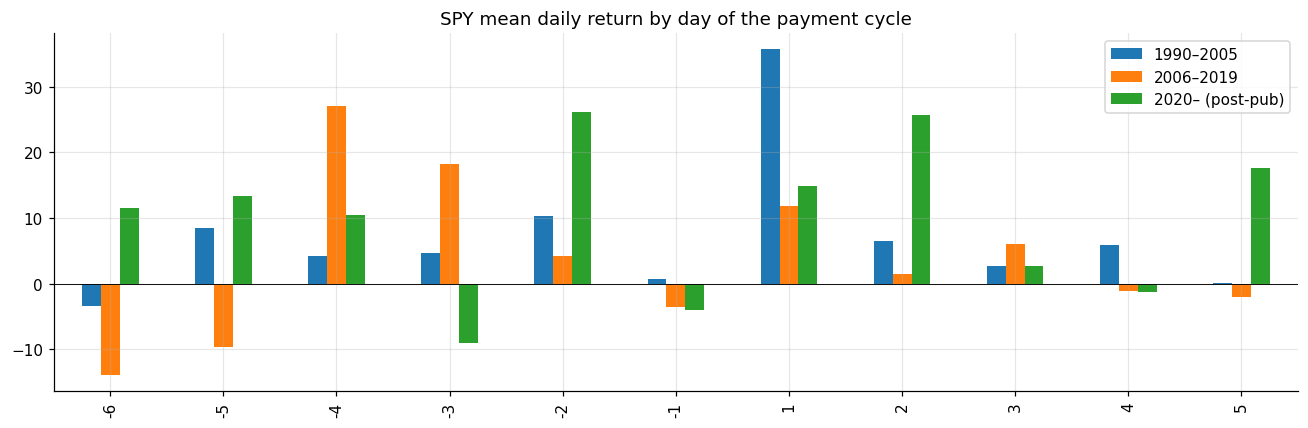

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3, "axes.spines.top": False, "axes.spines.right": False})
p = pd.read_csv("data/etfs.csv", parse_dates=["date"]).pivot(index="date", columns="ticker", values="adj_close")
r = p.pct_change() * 1e4
cal = r.index[r.index >= "1990-01-01"]
spy = r.SPY.reindex(cal).fillna(r["^GSPC"].reindex(cal))
ym = cal.to_period("M"); s = pd.Series(np.arange(len(cal)), index=cal)
dlast = s.groupby(ym).transform(lambda x: x - x.max()); dfirst = s.groupby(ym).transform(lambda x: x - x.min() + 1)
rel = pd.Series(np.where(dfirst <= 10, dfirst, dlast - 1), index=cal)      # -1 = last trading day, +1 = first
ERAS = [("1990–2005", cal < "2006"), ("2006–2019", (cal >= "2006") & (cal < "2020")), ("2020– (post-pub)", cal >= "2020")]
tab = pd.DataFrame({name: spy[m].groupby(rel[m]).mean() for name, m in ERAS}).loc[[-6, -5, -4, -3, -2, -1, 1, 2, 3, 4, 5]]
print("mean SPY return (bp) by trading day relative to month-end:"); print(tab.round(1).T.to_string())
tab.plot.bar(figsize=(12, 4)); plt.axhline(0, c="k", lw=0.6); plt.title("SPY mean daily return by day of the payment cycle"); plt.tight_layout(); plt.show()

## 2. Turn-of-month vs other days, and the timing strategy

In [2]:
rows = []
for name, m in ERAS:
    tom = rel[m].isin([-1, 1, 2, 3]); a, b = spy[m][tom], spy[m][~tom]
    t, _ = stats.ttest_ind(a, b, equal_var=False)
    pre = rel[m].isin([-6, -5, -4]); c = spy[m][pre]
    st = spy[m].where(tom, 0)
    rows.append({"era": name, "TOM bp/day": a.mean(), "other bp/day": b.mean(), "t (TOM-other)": t, "pre (-6..-4) bp/day": c.mean(),
                 "TOM-only Sharpe": st.mean() / st.std() * np.sqrt(252), "buy&hold Sharpe": spy[m].mean() / spy[m].std() * np.sqrt(252),
                 "TOM share of return": a.sum() / spy[m].sum()})
print(pd.DataFrame(rows).round(2).to_string(index=False))

             era  TOM bp/day  other bp/day  t (TOM-other)  pre (-6..-4) bp/day  TOM-only Sharpe  buy&hold Sharpe  TOM share of return
       1990–2005       11.40          2.54           2.07                 3.12             0.73             0.64                 0.51
       2006–2019        3.94          4.26          -0.07                 1.18             0.24             0.56                 0.18
2020– (post-pub)        9.83          5.67           0.57                11.76             0.59             0.82                 0.29


**Interpretation.**
- **1990–2005: the classic effect.** Turn-of-month days earn +11bp/day vs +2.5 otherwise (t = 2.1). Half the
  index's return comes from 19% of days, mostly the first trading day (+36bp).
- **2006–2019: gone.** 3.9bp vs 4.3bp (t ≈ −0.1). The dash-for-cash pre-window (days −6/−5) is negative, but days −4/−3
  are strongly positive, which is not the paper's shape.
- **2020–: no comeback.** 9.8 vs 5.7bp (t ≈ 0.6). Holding the market only on turn-of-month days has a lower Sharpe
  than just holding it (0.59 vs 0.82).

## 3. Takeaways
**Verdict: dead.** The payment-cycle anomaly was arbitraged or diluted after the mid-2000s and has not returned
post-publication. Not tradable.